# CREDIT RISK PREDICTION — MEMBER 1: LOGISTIC REGRESSION

**CS114 · Home Credit Default Risk · Notebook dành cho thành viên Logistic Regression**

Notebook này sử dụng **đúng pipeline dùng chung** `src.data_loader.get_train_test_data(scale=True)` và hàm đánh giá `src.metrics.evaluate_and_save()`, **không sửa** `src/`, không tự chia lại dữ liệu, không lấy kết quả từ notebook Kaggle khác để so sánh.

**Đầu ra:** `results/member1_logistic_regression.json` (đúng tên file theo hướng dẫn Git), Confusion Matrix, ROC/PR Curves, báo cáo hệ số và danh sách cải tiến.

> **Quan trọng:** Báo cáo EDA trước đó chỉ phân tích kỹ `application_train.csv`. Pipeline thực tế của nhóm gộp **5 bảng phụ khác** và **không đọc `bureau_balance.csv`**. Notebook này làm theo repo đang dùng, không áp đặt cấu trúc dữ liệu cũ.

> **Độ tin cậy:** `neighbors_target_mean_500` và Ridge selection hiện được fit trước khi chia các fold CV. **CV có thể lạc quan** do phụ thuộc nhãn của các fold khác. Đồng thời, `installments_payments.csv` có nguy cơ chứa giao dịch sau ngày đăng ký do core chưa lọc `DAYS_ENTRY_PAYMENT <= 0`. Không được gọi toàn bộ pipeline là đã chứng minh không leakage cho đến khi nhóm trưởng kiểm tra/sửa core. Xem file `REVIEW_DATA_LOADER.md` đi kèm.

## 1. Chuẩn bị môi trường (Windows / VS Code)

Notebook đặt ngay tại **thư mục gốc repository** `Credit_risk_CS114/`, cùng cấp với `src/`, `data/`, `requirements.txt`.

Lệnh cài đặt trong Terminal đang kích hoạt `(.venv)`:

```powershell
python -m pip install -r requirements.txt
python -m pip install ipykernel
```

Sau đó mở notebook trong VS Code → **Select Kernel → .venv**. **Không chạy pip ở mỗi lần chạy notebook.**

**6 file CSV bắt buộc** trong `data/`:

- `application_train.csv`
- `bureau.csv`
- `previous_application.csv`
- `installments_payments.csv`
- `POS_CASH_balance.csv`
- `credit_card_balance.csv`

Nếu thiếu bất kỳ file nào, notebook sẽ dừng để tránh tình huống `data_loader.py` tự bỏ qua bảng phụ, làm kết quả của ba thành viên khác nhau. Không cần `bureau_balance.csv` theo code nhóm hiện tại.

In [1]:
from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve, balanced_accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss
)

# Chạy notebook ở gốc repo (mở VS Code workspace tại Credit_risk_CS114).
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'data_loader.py').is_file():
    raise RuntimeError(
        'Bạn cần mở notebook tại thư mục gốc repository (nơi có src/data_loader.py). '
        f'Thư mục hiện tại: {PROJECT_ROOT}'
    )

from src.config import RANDOM_STATE, TEST_SIZE, DATA_DIR, RESULTS_DIR
from src.data_loader import get_train_test_data
from src.metrics import evaluate_and_save, plot_confusion_matrix

print('Working directory:', PROJECT_ROOT)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('Group config: random_state =', RANDOM_STATE, '| test_size =', TEST_SIZE)

Working directory: d:\lt cho ML\đồ án\Credit_risk_CS114
Python: 3.14.3
scikit-learn: 1.9.1
Group config: random_state = 1 | test_size = 0.25


## 2. Data inventory — kiểm tra đủ **6 CSV gốc**

Bước này chỉ kiểm tra tên file và dung lượng; chưa tải toàn bộ dữ liệu vào RAM. **Không push thư mục `data/` lên Git.**

In [2]:
REQUIRED_CSV = [
    'application_train.csv', 'bureau.csv', 'previous_application.csv',
    'installments_payments.csv', 'POS_CASH_balance.csv',
    'credit_card_balance.csv'
]
file_status = pd.DataFrame([
    {'file': name, 'exists': (DATA_DIR / name).is_file(),
     'size_MiB': round((DATA_DIR / name).stat().st_size / (1024 ** 2), 1)
                 if (DATA_DIR / name).is_file() else None}
    for name in REQUIRED_CSV
])
display(file_status)
missing = file_status.loc[~file_status['exists'], 'file'].tolist()
if missing:
    raise FileNotFoundError('Thiếu dữ liệu trong data/: ' + ', '.join(missing))
print('✅ Đủ 6 file CSV. Có thể chạy data_loader chung.')

,file,exists,size_MiB
0,application_train.csv,True,158.4
1,bureau.csv,True,162.1
2,previous_application.csv,True,386.2
3,installments_payments.csv,True,689.6
4,POS_CASH_balance.csv,True,374.5
5,credit_card_balance.csv,True,404.9


✅ Đủ 6 file CSV. Có thể chạy data_loader chung.


## 3. Nạp đúng dataset chung của nhóm (cell nặng nhất)

Hàm dưới đây tự chạy Feature Engineering, gộp 5 bảng lịch sử, mã hóa, chia train/test `75/25`, tạo `neighbors_target_mean_500`, điền khuyết, chuẩn hóa và Ridge chọn feature theo `src/config.py`.

**Cell này có thể nặng với RAM 16 GB**. Nên đóng ứng dụng khác và **không chạy lại cell này mỗi lần thử siêu tham số**; sau lần tải đầu, chỉ chạy lại các cell Modeling bên dưới.

In [3]:
start = time.perf_counter()
X_train, X_test, y_train, y_test, feature_names = get_train_test_data(
    scale=True
)
elapsed = time.perf_counter() - start
print(f'Loaded data in {elapsed/60:.1f} minutes')
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Features:', len(feature_names))
print('Train TARGET=1:', f'{np.mean(y_train):.2%}')
print('Test  TARGET=1:', f'{np.mean(y_test):.2%}')

[OK] Đã ghép đặc trưng từ bureau.csv
[OK] Đã ghép đặc trưng từ previous_application.csv
[OK] Đã ghép đặc trưng từ installments_payments.csv
[OK] Đã ghép đặc trưng từ POS_CASH_balance.csv
[OK] Đã ghép đặc trưng từ credit_card_balance.csv
Hoàn tất ghép bảng phụ sau 11.62s | Shape: (307511, 182)
[OK] Đã tạo neighbors_target_mean_500 (leak-free) trong 30.82s
Đặc trưng được chọn: 122 / 198 (Ridge Selection)
Train samples: 230,633 | high_risk (1): 18,619 (8.07%)
Test samples : 76,878 | high_risk (1): 6,206 (8.07%)
Loaded data in 0.8 minutes
X_train: (230633, 122) | X_test: (76878, 122)
Features: 122
Train TARGET=1: 8.07%
Test  TARGET=1: 8.07%


## 4. Diagnostics sau preprocessing (không phải EDA raw)

Kiểm tra dữ liệu sau khi xử lý: kích thước, lớp mục tiêu, tính hữu hạn, feature từ các nguồn khác nhau. Phần EDA raw trong báo cáo cũ chỉ là EDA `application_train`; bảng tổng hợp từ 5 bảng phụ do core xử lý.

,dataset,n_samples,TARGET_0,TARGET_1,TARGET_1_rate
0,Train,230633,212014,18619,0.080730
1,Test,76878,70672,6206,0.080725


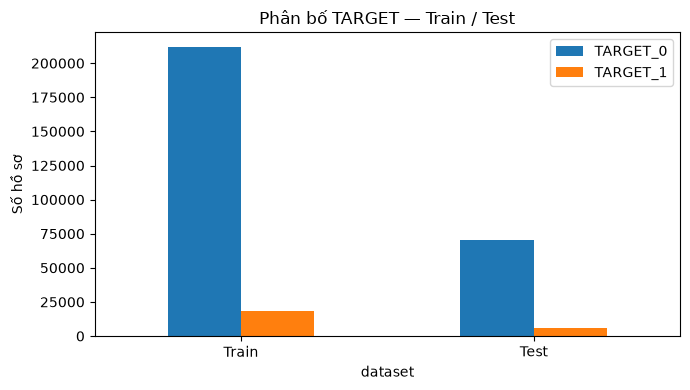

,group,selected_features
0,Application / EXT_SOURCE,32
1,Installments,5
2,Bureau,8
3,Previous application,7
4,POS / Cash,3
5,Credit card,2
6,KNN target feature,1


Selected features (first 25): ['neighbors_target_mean_500', 'DAYS_EMPLOYED_ANOM', 'AMT_CREDIT', 'FLAG_EMP_PHONE', 'AMT_GOODS_PRICE', 'AGE_INT', 'CODE_GENDER', 'FLAG_DOCUMENT_3', 'pos_count', 'YEARS_BUILD_AVG', 'BASEMENTAREA_AVG', 'bureau_active_count', 'ANNUITY_INCOME_PERCENT', 'DAYS_BIRTH', 'BASEMENTAREA_MEDI', 'EXT_SOURCE_MEAN', 'DAYS_EMPLOYED_PERCENT', 'credit_goods_price_ratio', 'inst_past_due_rate', 'prev_refused_rate', 'YEARS_BUILD_MEDI', 'EXT_SOURCE_MIN', 'REGION_RATING_CLIENT_W_CITY', 'inst_365_past_due_rate', 'prev_days_decision_mean']
⚠️ Cảnh báo: train-side CV chưa hoàn toàn leak-free vì target-neighbor feature được dựng trước CV.


In [4]:
y_train = np.asarray(y_train, dtype=np.int8)
y_test = np.asarray(y_test, dtype=np.int8)

assert X_train.ndim == 2 and X_test.ndim == 2
assert X_train.shape[1] == X_test.shape[1] == len(feature_names)
assert len(y_train) == X_train.shape[0] and len(y_test) == X_test.shape[0]
assert np.isin(y_train, [0,1]).all() and np.isin(y_test, [0,1]).all()
assert np.isfinite(X_train).all() and np.isfinite(X_test).all(), 'Dữ liệu sau preprocessing có NaN/Inf!'

label_table = pd.DataFrame({
    'dataset': ['Train', 'Test'],
    'n_samples': [len(y_train), len(y_test)],
    'TARGET_0': [int((y_train == 0).sum()), int((y_test == 0).sum())],
    'TARGET_1': [int((y_train == 1).sum()), int((y_test == 1).sum())],
    'TARGET_1_rate': [float(y_train.mean()), float(y_test.mean())],
})
display(label_table)

ax = label_table.set_index('dataset')[['TARGET_0','TARGET_1']].plot.bar(
    figsize=(7,4), rot=0, title='Phân bố TARGET — Train / Test'
)
ax.set_ylabel('Số hồ sơ')
plt.tight_layout()
plt.show()

prefix_groups = {
    'Application / EXT_SOURCE': ['EXT_SOURCE', 'AMT_', 'DAYS_', 'AGE_', 'CREDIT_', 'NAME_'],
    'Installments': ['inst_', 'installment_', 'annuity_to_max_installment'],
    'Bureau': ['bureau_', 'DAYS_CREDIT', 'debt_credit_ratio', 'last_active_'],
    'Previous application': ['prev_'],
    'POS / Cash': ['pos_'],
    'Credit card': ['cc_'],
    'KNN target feature': ['neighbors_target_mean_'],
}
feature_counts = {
    group: sum(any(str(name).startswith(p) for p in prefixes) for name in feature_names)
    for group, prefixes in prefix_groups.items()
}
display(pd.DataFrame({'group':list(feature_counts), 'selected_features':list(feature_counts.values())}))
print('Selected features (first 25):', feature_names[:25])
if 'neighbors_target_mean_500' in feature_names:
    print('⚠️ Cảnh báo: train-side CV chưa hoàn toàn leak-free vì target-neighbor feature được dựng trước CV.')

## 5. Thiết kế Logistic Regression và điều kiện so sánh

- **Mô hình chính:** `LogisticRegression(solver='liblinear', penalty='l2')`.
- **Baseline của nhóm:** `C=1`, `class_weight=None`, threshold cố định `0.5`.
- **Tuning:** thử `C` và `class_weight`, chấm theo **Balanced Accuracy** như README. Đồng thời lưu ROC-AUC và AP từ CV để tham khảo.
- **Test:** chỉ đánh giá ở cuối một lần, threshold `0.5` cố định; không xem các đường PR/ROC trên test rồi đổi threshold để tăng điểm.

⚠️ **Chú ý về CV:** Vì shared loader tạo `neighbors_target_mean_500` và chọn feature bằng Ridge trên toàn bộ train trước các fold, điểm CV dưới đây có nguy cơ *optimistic bias*. Kết quả CV là **thăm dò cấu hình**, không phải bằng chứng chắc chắn không leakage. Cần sửa core của nhóm để tái tính supervised transformations trong từng fold nếu muốn công bố CV chuẩn.

In [5]:
# 4 cấu hình × 3 folds = 12 lượt fit; n_jobs=1 để hạn chế tăng đột biến RAM.
CV_FOLDS = 3
PARAM_GRID = {
    'C': [0.1, 1.0],
    'class_weight': [None, 'balanced'],
}

base_model = LogisticRegression(
    penalty='l2', solver='liblinear', max_iter=700,
    C=1.0, class_weight=None, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    estimator=base_model,
    param_grid=PARAM_GRID,
    scoring={
        'balanced_accuracy': 'balanced_accuracy',
        'roc_auc': 'roc_auc',
        'average_precision': 'average_precision',
    },
    refit='balanced_accuracy',
    cv=cv,
    n_jobs=1,
    verbose=1,
    return_train_score=False,
    error_score='raise',
)
print('Cấu hình thử:', len(PARAM_GRID['C']) * len(PARAM_GRID['class_weight']))
print('Số lượt CV:', CV_FOLDS * len(PARAM_GRID['C']) * len(PARAM_GRID['class_weight']))

Cấu hình thử: 4
Số lượt CV: 12


## 6. Tuning trên training set

Không dùng `X_test` hoặc `y_test` để chọn tham số. Nếu máy có RAM 16 GB, giữ `n_jobs=1`; không mở nhiều notebook ML đồng thời.

In [6]:
t_fit = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    search.fit(X_train, y_train)
print(f'GridSearch + refit: {(time.perf_counter()-t_fit)/60:.1f} phút')
print('Best params:', search.best_params_)
print('Best exploratory CV balanced accuracy:', f'{search.best_score_:.4f}')
if caught:
    display(pd.DataFrame({'warning': [str(w.message) for w in caught[:5]]}))

cv_table = pd.DataFrame(search.cv_results_)[[
    'param_C', 'param_class_weight', 'mean_test_balanced_accuracy',
    'mean_test_roc_auc', 'mean_test_average_precision',
    'std_test_balanced_accuracy', 'rank_test_balanced_accuracy'
]].sort_values('rank_test_balanced_accuracy').reset_index(drop=True)
display(cv_table)
print('⚠️ CV scores exploratory only: KNN target encoding + Ridge selection are prefit on full train.')

Fitting 3 folds for each of 4 candidates, totalling 12 fits
GridSearch + refit: 3.3 phút
Best params: {'C': 0.1, 'class_weight': 'balanced'}
Best exploratory CV balanced accuracy: 0.6944


,warning
0,'penalty' was deprecated in version 1.8 and wi...
1,'penalty' was deprecated in version 1.8 and wi...
2,'penalty' was deprecated in version 1.8 and wi...
3,'penalty' was deprecated in version 1.8 and wi...
4,'penalty' was deprecated in version 1.8 and wi...


,param_C,param_class_weight,mean_test_balanced_accuracy,mean_test_roc_auc,mean_test_average_precision,std_test_balanced_accuracy,rank_test_balanced_accuracy
0,0.1,balanced,0.694413,0.761771,0.243498,0.001123,1
1,1.0,balanced,0.694213,0.761707,0.243422,0.001246,2
2,1.0,NaN,0.510891,0.761621,0.245321,0.001483,3
3,0.1,NaN,0.510781,0.761727,0.245311,0.001467,4


⚠️ CV scores exploratory only: KNN target encoding + Ridge selection are prefit on full train.


## 7. Đánh giá cuối cùng trên tập TEST chung của nhóm

Chỉ dùng `search.best_estimator_` (đã refit trên toàn bộ train), dự đoán xác suất trên test, lấy threshold **0.5** như README, sau đó dùng trực tiếp `evaluate_and_save()` và `plot_confusion_matrix()`.

Các chỉ số thêm **Average Precision, Brier Score** chỉ in trong notebook, không thay đổi schema JSON chung.


EVALUATION REPORT: Logistic Regression
Balanced Accuracy : 0.6975
ROC-AUC           : 0.7655
Overall Accuracy  : 0.7033

Confusion Matrix (rows=Actual [0, 1], cols=Predicted [0, 1]):
[[49779 20893]
 [ 1920  4286]]

Classification Report:
               precision    recall  f1-score   support

 low_risk (0)       0.96      0.70      0.81     70672
high_risk (1)       0.17      0.69      0.27      6206

     accuracy                           0.70     76878
    macro avg       0.57      0.70      0.54     76878
 weighted avg       0.90      0.70      0.77     76878

Saved metrics to D:\lt cho ML\đồ án\Credit_risk_CS114\results\member1_logistic_regression.json


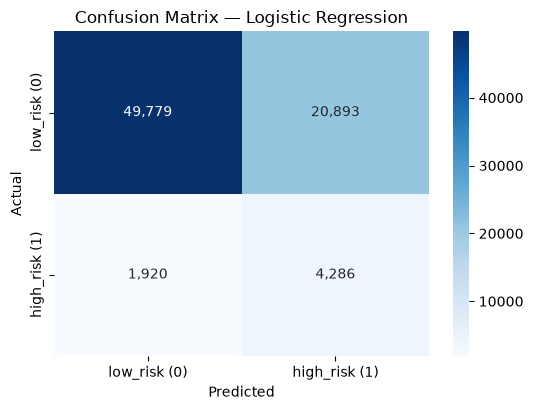

,Metric,Value
0,Average Precision,0.247910
1,Brier Score,0.196908
2,Baseline prevalence TARGET=1,0.080725
3,Balanced Accuracy,0.697494
4,High Risk Precision,0.170221
5,High Risk Recall,0.690622
6,High Risk F1,0.273124


JSON chuẩn nhóm: D:\lt cho ML\đồ án\Credit_risk_CS114\results\member1_logistic_regression.json


In [7]:
best_model = search.best_estimator_
y_prob = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(np.int8)

metrics = evaluate_and_save(
    model_name='Logistic Regression',
    filename='member1_logistic_regression',
    y_true=y_test,
    y_pred=y_pred,
    y_prob=y_prob,
)
plot_confusion_matrix(y_test, y_pred, model_name='Logistic Regression')

extra_metrics = {
    'Average Precision': average_precision_score(y_test, y_prob),
    'Brier Score': brier_score_loss(y_test, y_prob),
    'Baseline prevalence TARGET=1': np.mean(y_test),
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
    'High Risk Precision': precision_score(y_test, y_pred, zero_division=0),
    'High Risk Recall': recall_score(y_test, y_pred, zero_division=0),
    'High Risk F1': f1_score(y_test, y_pred, zero_division=0),
}
display(pd.DataFrame({'Metric': list(extra_metrics.keys()),
                      'Value': [float(x) for x in extra_metrics.values()]}))
print('JSON chuẩn nhóm:', RESULTS_DIR / 'member1_logistic_regression.json')

## 8. Biểu đồ ROC Curve, Precision–Recall Curve và Confusion Matrix

Đồ thị test dùng **để báo cáo và chẩn đoán**, không dùng để tự thay đổi hyperparameters/threshold sau khi nhìn kết quả.

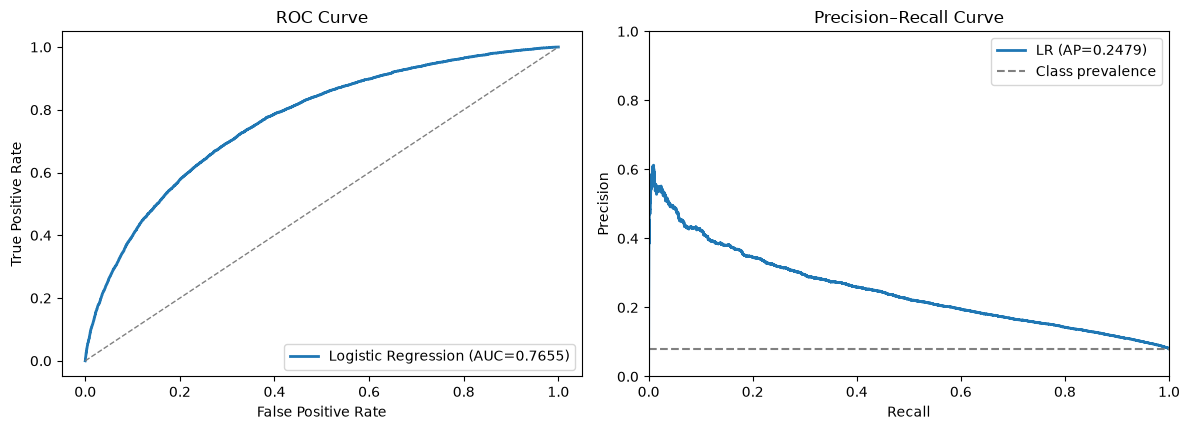

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(fpr, tpr, lw=2, label=f'Logistic Regression (AUC={roc_auc_score(y_test,y_prob):.4f})')
axes[0].plot([0,1], [0,1], '--', linewidth=1, color='gray')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC Curve')
axes[0].legend(loc='lower right')
axes[1].plot(recall_curve, precision_curve, lw=2,
             label=f'LR (AP={average_precision_score(y_test,y_prob):.4f})')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label='Class prevalence')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall Curve', xlim=(0,1), ylim=(0,1))
axes[1].legend()
plt.tight_layout()
plt.show()

## 9. Error Analysis — mô hình bỏ sót/cảnh báo nhầm bao nhiêu?

`FN`: thực sự TARGET=1 nhưng dự đoán 0; `FP`: TARGET=0 nhưng dự đoán 1. Đây là hai kiểu lỗi cần phân tích vì chúng liên quan đến khả năng phát hiện khó khăn thanh toán.

,Error group,Count
0,True Negative (TN),49779
1,False Positive (FP),20893
2,False Negative (FN),1920
3,True Positive (TP),4286


Số trường hợp TARGET=1 bị bỏ sót: 1920 / 6206
Tỷ lệ bỏ sót TARGET=1: 30.94%
Tỷ lệ cảnh báo nhầm trong các cảnh báo: 82.98%


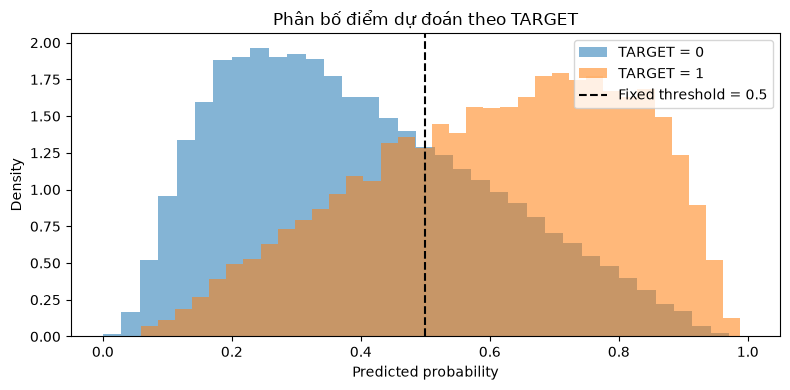

In [9]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
error_table = pd.DataFrame([
    {'Error group':'True Negative (TN)', 'Count':int(tn)},
    {'Error group':'False Positive (FP)', 'Count':int(fp)},
    {'Error group':'False Negative (FN)', 'Count':int(fn)},
    {'Error group':'True Positive (TP)', 'Count':int(tp)},
])
display(error_table)
print('Số trường hợp TARGET=1 bị bỏ sót:', int(fn), '/', int(fn + tp))
print('Tỷ lệ bỏ sót TARGET=1:', f'{fn/(fn+tp):.2%}' if fn+tp else 'N/A')
print('Tỷ lệ cảnh báo nhầm trong các cảnh báo:', f'{fp/(fp+tp):.2%}' if fp+tp else 'N/A')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_prob[y_test==0], bins=35, alpha=.55, density=True, label='TARGET = 0')
ax.hist(y_prob[y_test==1], bins=35, alpha=.55, density=True, label='TARGET = 1')
ax.axvline(.5, linestyle='--', color='black', label='Fixed threshold = 0.5')
ax.set(xlabel='Predicted probability', ylabel='Density', title='Phân bố điểm dự đoán theo TARGET')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Giải thích hệ số Logistic Regression

Vì shared loader `scale=True`, độ lớn hệ số thể hiện mức nhạy của mô hình với biến đầu vào sau chuẩn hóa. Tuy nhiên, feature categorical đang bị **mã hóa thành số nguyên có thứ tự** trong core, nên dấu/hệ số của một số biến phân loại không nên diễn giải như quan hệ tuyến tính thực tế.

Hệ số phản ánh **liên hệ mô hình đã học**, không chứng minh nguyên nhân làm khách hàng gặp khó khăn thanh toán.

,Feature,Coefficient,AbsCoeff
2,AMT_CREDIT,0.415161,0.415161
4,AMT_GOODS_PRICE,-0.375633,0.375633
14,BASEMENTAREA_MEDI,0.322497,0.322497
10,BASEMENTAREA_AVG,-0.313058,0.313058
1,DAYS_EMPLOYED_ANOM,-0.221108,0.221108
112,EXT_SOURCE_3,-0.219787,0.219787
84,EXT_SOURCE_MAX,-0.211644,0.211644
53,credit_annuity_ratio,-0.204222,0.204222
50,EXT_SOURCE_STD,0.199713,0.199713
37,ELEVATORS_MODE,0.182760,0.182760


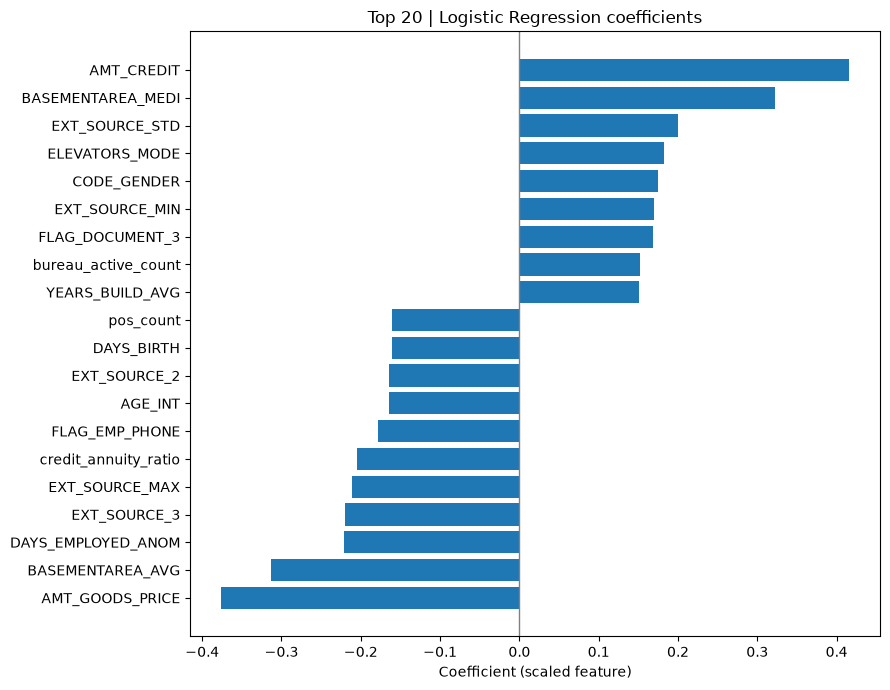

In [10]:
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': best_model.coef_.ravel()
})
coef_df['AbsCoeff'] = coef_df['Coefficient'].abs()
coef_top = coef_df.sort_values('AbsCoeff', ascending=False).head(20)
display(coef_top[['Feature','Coefficient','AbsCoeff']])

bar_data = coef_top.sort_values('Coefficient')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(bar_data['Feature'], bar_data['Coefficient'])
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='Coefficient (scaled feature)', title='Top 20 | Logistic Regression coefficients')
plt.tight_layout()
plt.show()

## 11. Gợi ý cải thiện dựa trên kết quả thực tế

Đây là định hướng nghiên cứu, **không tự thay đổi test set** để tối ưu kết quả. Khi nhóm trưởng sửa core và tạo được validation sạch, có thể thử penalty L1/Elastic Net, class weights và chọn threshold trên validation; sau đó chốt một lần trên test chung.

In [11]:
suggestions = []
if extra_metrics['High Risk Recall'] < 0.5:
    suggestions.append('Recall TARGET=1 còn thấp: thử class_weight và lựa chọn threshold trên validation sạch, không trên test.')
if extra_metrics['High Risk Precision'] < 0.25:
    suggestions.append('Precision TARGET=1 thấp: kiểm tra false positives và tăng chất lượng đặc trưng thay vì chỉ hạ threshold.')
if extra_metrics['Average Precision'] <= 2 * y_test.mean():
    suggestions.append('AP chưa cao so với prevalence: cần tăng chất lượng xếp hạng bằng đặc trưng lịch sử và kiểm tra missing values.')
if 'neighbors_target_mean_500' in feature_names:
    suggestions.append('Cần tái dựng neighbors_target_mean_500 riêng trong từng CV fold để đánh giá/tuning không bị target leakage.')
suggestions.append('Rà soát DAYS_ENTRY_PAYMENT <= 0 trước khi tổng hợp Installments để tránh dùng thanh toán tương lai.')
suggestions.append('Đề xuất nhóm trưởng áp dụng One-Hot Encoding cho categorical thay vì ép tất cả danh mục thành số nguyên có thứ tự.')
suggestions.append('Không so sánh trực tiếp metric với notebook Kaggle trước đó nếu khác split, bảng phụ hoặc cách chọn threshold.')

for i, s in enumerate(suggestions, start=1):
    print(f'{i}. {s}')

1. Precision TARGET=1 thấp: kiểm tra false positives và tăng chất lượng đặc trưng thay vì chỉ hạ threshold.
2. Cần tái dựng neighbors_target_mean_500 riêng trong từng CV fold để đánh giá/tuning không bị target leakage.
3. Rà soát DAYS_ENTRY_PAYMENT <= 0 trước khi tổng hợp Installments để tránh dùng thanh toán tương lai.
4. Đề xuất nhóm trưởng áp dụng One-Hot Encoding cho categorical thay vì ép tất cả danh mục thành số nguyên có thứ tự.
5. Không so sánh trực tiếp metric với notebook Kaggle trước đó nếu khác split, bảng phụ hoặc cách chọn threshold.


## 12. Quy định nộp và cách báo cáo

1. File notebook này ở gốc repo: `member1_logistic_regression.ipynb`.
2. Dữ liệu nguồn đặt ở `data/` và **không commit** CSV hoặc `.venv`.
3. File metric đúng chuẩn sinh ra tại `results/member1_logistic_regression.json`.
4. Chỉ commit file notebook và JSON của chính mình theo README; đổi `member1` thành số thành viên thực nếu cần. Trong trường hợp đổi tên, cần đổi cả `filename=` ở cell đánh giá.
5. Ghi rõ **CV là thăm dò** do target-derived KNN feature và Ridge selection nằm ngoài fold. Không khẳng định đã xử lý sạch leakage khi chưa kiểm chứng xử lý lịch sử.
6. Khi nhóm đã sửa pipeline chung, hãy chạy lại cả ba mô hình trên **cùng phiên bản** `src/data_loader.py` và cùng split.

**Các kết quả cần ghi trong báo cáo:** Balanced Accuracy, ROC-AUC, Average Precision, Precision/Recall/F1 của TARGET=1, Confusion Matrix, tham số LR được chọn và nhận xét ưu/nhược điểm.

**Giới hạn:** Notebook chưa có kết quả Home Credit thật vì ở đây chỉ nhận code và notebook chuẩn, không có 6 CSV dữ liệu. Thời gian tải dữ liệu phụ thuộc RAM/CPU local.